In [1]:
# # NSE Stocks EDA

# ## FINAURA — AI-Based Financial Market Regime Detection, Risk Forecasting & Portfolio Analytics

# This notebook performs Exploratory Data Analysis on the processed NSE stock dataset.

# ### Objectives
# - Understand the structure and quality of the dataset
# - Analyze stock price trends
# - Analyze daily and log returns
# - Study volatility behavior
# - Analyze moving averages and momentum
# - Examine drawdowns
# - Analyze trading volume
# - Compare the selected NSE stocks
# - Study stock-to-stock correlations
# - Analyze the future 5-day volatility target
# - Identify relationships between features and the prediction target

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

import seaborn as sns

from pathlib import Path

pd.set_option("display.max_columns", None)
pd.set_option("display.max_rows", 100)

print("Libraries imported successfully.")

Libraries imported successfully.


In [3]:
input_path = Path("../data/processed/nse_stocks_processed.csv")

print("Input file:")
print(input_path)

Input file:
..\data\processed\nse_stocks_processed.csv


In [4]:
df = pd.read_csv(input_path)

print("Dataset loaded successfully.")
print("Shape:", df.shape)

Dataset loaded successfully.
Shape: (18744, 25)


In [5]:
df.head()

,date,symbol,open,high,low,close,adj_close,volume,daily_return,log_return,intraday_return,price_range,ma_5,ma_10,ma_20,ma_50,volatility_5d,volatility_10d,volatility_20d,momentum_5d,momentum_20d,drawdown,volume_ma_20,volume_ratio,target_5d_volatility
0,2017-03-15,HDFCBANK,352.737488,355.000000,352.637512,354.149994,322.995026,4271860,0.004182,0.004174,0.004004,0.006671,350.689990,348.237494,345.869373,326.772249,0.034354,0.070173,0.163776,0.021930,0.081209,0.0,26102606.8,0.163656,0.043742
1,2017-03-16,HDFCBANK,354.524994,355.712494,353.412506,354.337494,323.166046,4980108,0.000529,0.000529,-0.000529,0.006491,351.947491,348.879993,347.197498,327.873499,0.043742,0.070415,0.163818,0.018065,0.081039,0.0,26229309.2,0.189868,0.041542
2,2017-03-17,HDFCBANK,354.637512,356.875000,353.212494,356.462494,325.104065,3390464,0.005997,0.005979,0.005146,0.010275,353.529993,350.023743,348.493123,329.053248,0.041542,0.044430,0.163148,0.022701,0.078392,0.0,26092485.4,0.129940,0.045417
3,2017-03-20,HDFCBANK,356.662506,359.962494,356.487488,359.024994,327.441101,8142344,0.007189,0.007163,0.006624,0.009679,355.329993,351.501242,349.845622,330.306248,0.045417,0.036086,0.163586,0.025712,0.081482,0.0,26247417.6,0.310215,0.040547
4,2017-03-21,HDFCBANK,358.500000,361.250000,358.500000,360.237488,328.546997,5557280,0.003377,0.003371,0.004847,0.007634,356.842493,353.006241,350.644371,331.579998,0.040547,0.035479,0.109982,0.021443,0.046403,0.0,6412283.6,0.866662,0.089630


In [6]:
df.tail()

,date,symbol,open,high,low,close,adj_close,volume,daily_return,log_return,intraday_return,price_range,ma_5,ma_10,ma_20,ma_50,volatility_5d,volatility_10d,volatility_20d,momentum_5d,momentum_20d,drawdown,volume_ma_20,volume_ratio,target_5d_volatility
18739,2026-08-26,TCS,2305.100098,2306.300049,2266.399902,2270.000000,2270.000000,1660737,-0.011410,-0.011476,-0.015227,0.017577,2290.06001,2306.85000,2362.969995,2240.720012,0.119078,0.159834,0.307152,-0.008301,-0.072182,-0.501510,2917245.00,0.569283,0.117663
18740,2026-08-27,TCS,2270.000000,2283.600098,2243.899902,2248.399902,2248.399902,1709113,-0.009515,-0.009561,-0.009515,0.017657,2280.13999,2294.18999,2353.799988,2241.622009,0.117663,0.140809,0.307752,-0.021584,-0.075417,-0.506253,2757621.55,0.619778,0.347443
18741,2026-08-28,TCS,2272.000000,2348.500000,2263.300049,2342.000000,2342.000000,4054069,0.041630,0.040786,0.030810,0.036379,2288.13999,2292.28999,2352.619983,2245.962009,0.347443,0.271379,0.332690,0.017376,-0.009976,-0.485699,2743140.85,1.477893,0.356259
18742,2026-08-31,TCS,2342.000000,2399.300049,2306.199951,2399.300049,2399.300049,2905846,0.024466,0.024172,0.024466,0.038803,2311.17998,2300.90000,2348.899988,2251.392009,0.356259,0.273379,0.302322,0.050436,-0.030076,-0.473116,2736591.20,1.061849,0.391878
18743,2026-09-01,TCS,2355.000000,2372.000000,2325.000000,2369.000000,2369.000000,2678034,-0.012629,-0.012709,0.005945,0.019840,2325.73999,2309.80000,2344.349988,2257.580007,0.391878,0.270261,0.304645,0.031705,-0.036992,-0.479769,2730853.30,0.980658,0.384916


In [7]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 18744 entries, 0 to 18743
Data columns (total 25 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   date                  18744 non-null  object 
 1   symbol                18744 non-null  object 
 2   open                  18744 non-null  float64
 3   high                  18744 non-null  float64
 4   low                   18744 non-null  float64
 5   close                 18744 non-null  float64
 6   adj_close             18744 non-null  float64
 7   volume                18744 non-null  int64  
 8   daily_return          18744 non-null  float64
 9   log_return            18744 non-null  float64
 10  intraday_return       18744 non-null  float64
 11  price_range           18744 non-null  float64
 12  ma_5                  18744 non-null  float64
 13  ma_10                 18744 non-null  float64
 14  ma_20                 18744 non-null  float64
 15  ma_50              

In [8]:
rows, columns = df.shape

print("Number of rows:", rows)
print("Number of columns:", columns)

Number of rows: 18744
Number of columns: 25


In [9]:
print("Available columns:")
for col in df.columns:
    print(col)

Available columns:
date
symbol
open
high
low
close
adj_close
volume
daily_return
log_return
intraday_return
price_range
ma_5
ma_10
ma_20
ma_50
volatility_5d
volatility_10d
volatility_20d
momentum_5d
momentum_20d
drawdown
volume_ma_20
volume_ratio
target_5d_volatility


In [10]:
print("Data types:")
print(df.dtypes)

Data types:
date                     object
symbol                   object
open                    float64
high                    float64
low                     float64
close                   float64
adj_close               float64
volume                    int64
daily_return            float64
log_return              float64
intraday_return         float64
price_range             float64
ma_5                    float64
ma_10                   float64
ma_20                   float64
ma_50                   float64
volatility_5d           float64
volatility_10d          float64
volatility_20d          float64
momentum_5d             float64
momentum_20d            float64
drawdown                float64
volume_ma_20            float64
volume_ratio            float64
target_5d_volatility    float64
dtype: object


In [11]:
df["date"] = pd.to_datetime(df["date"], errors="coerce")

print("Date conversion completed.")
print(df["date"].dtype)

Date conversion completed.
datetime64[ns]


In [12]:
stocks = sorted(df["symbol"].dropna().unique())

print("Stocks in dataset:")
for stock in stocks:
    print(stock)

print("\nNumber of stocks:", len(stocks))

Stocks in dataset:
HDFCBANK
ICICIBANK
INFY
ITC
LT
RELIANCE
SBIN
TCS

Number of stocks: 8


In [13]:
stock_counts = df["symbol"].value_counts().sort_index()

print("Records per stock:")
print(stock_counts)

Records per stock:
symbol
HDFCBANK     2343
ICICIBANK    2343
INFY         2343
ITC          2343
LT           2343
RELIANCE     2343
SBIN         2343
TCS          2343
Name: count, dtype: int64


In [14]:
print("Overall date range:")
print("Start:", df["date"].min())
print("End:", df["date"].max())

Overall date range:
Start: 2017-03-15 00:00:00
End: 2026-09-01 00:00:00


In [15]:
date_range_by_stock = (
    df.groupby("symbol")["date"]
    .agg(["min", "max"])
    .sort_index()
)

date_range_by_stock

,min,max
symbol,,
HDFCBANK,2017-03-15,2026-09-01
ICICIBANK,2017-03-15,2026-09-01
INFY,2017-03-15,2026-09-01
ITC,2017-03-15,2026-09-01
LT,2017-03-15,2026-09-01
RELIANCE,2017-03-15,2026-09-01
SBIN,2017-03-15,2026-09-01
TCS,2017-03-15,2026-09-01


In [16]:
missing_values = df.isnull().sum()

print("Missing values:")
print(missing_values)

Missing values:
date                    0
symbol                  0
open                    0
high                    0
low                     0
close                   0
adj_close               0
volume                  0
daily_return            0
log_return              0
intraday_return         0
price_range             0
ma_5                    0
ma_10                   0
ma_20                   0
ma_50                   0
volatility_5d           0
volatility_10d          0
volatility_20d          0
momentum_5d             0
momentum_20d            0
drawdown                0
volume_ma_20            0
volume_ratio            0
target_5d_volatility    0
dtype: int64


In [17]:
duplicate_rows = df.duplicated().sum()

print("Duplicate rows:", duplicate_rows)

Duplicate rows: 0


In [18]:
df.describe()

,date,open,high,low,close,adj_close,volume,daily_return,log_return,intraday_return,price_range,ma_5,ma_10,ma_20,ma_50,volatility_5d,volatility_10d,volatility_20d,momentum_5d,momentum_20d,drawdown,volume_ma_20,volume_ratio,target_5d_volatility
count,18744,18744.000000,18744.000000,18744.000000,18744.000000,18744.000000,1.874400e+04,18744.000000,18744.000000,18744.000000,18744.000000,18744.000000,18744.000000,18744.000000,18744.000000,18744.000000,18744.000000,18744.000000,18744.000000,18744.000000,18744.000000,1.874400e+04,18744.000000,18744.000000
mean,2021-12-09 22:56:41.792573440,1176.610228,1187.962120,1164.609128,1176.026891,1092.206082,1.425046e+07,0.000571,0.000428,-0.000479,0.021051,1175.167411,1174.088699,1171.906408,1165.328694,0.223830,0.234445,0.241395,0.002866,0.011779,-0.122424,1.426148e+07,1.009567,0.223860
min,2017-03-15 00:00:00,142.511459,146.363113,129.608398,141.789276,104.390175,0.000000e+00,-0.178478,-0.196597,-0.135786,0.000000,147.354922,149.622586,157.037034,164.384075,0.016310,0.035479,0.071209,-0.295110,-0.480804,-0.594925,1.217160e+06,0.000000,0.016310
25%,2019-07-29 00:00:00,454.059891,459.052391,448.742126,454.186592,409.686699,4.418762e+06,-0.007881,-0.007912,-0.008295,0.013381,453.405498,453.788501,453.159296,449.209437,0.132843,0.155426,0.171910,-0.017520,-0.030900,-0.173967,5.157190e+06,0.691587,0.132857
50%,2021-12-10 00:00:00,840.875000,848.487518,833.549988,840.687500,808.066437,1.022779e+07,0.000227,0.000227,-0.000735,0.018091,839.879999,838.598755,836.043123,824.706000,0.189218,0.205106,0.215797,0.002228,0.009438,-0.087790,1.191762e+07,0.886661,0.189265
75%,2024-04-26 00:00:00,1450.299957,1463.850037,1436.000000,1449.156250,1379.784180,1.792387e+07,0.008614,0.008577,0.007000,0.024848,1446.869995,1447.681873,1448.138753,1446.448251,0.269197,0.274624,0.277940,0.022528,0.054593,-0.034368,1.825722e+07,1.172235,0.269226
max,2026-09-01 00:00:00,4576.000000,4592.250000,4512.000000,4553.750000,4375.364258,4.453421e+08,0.276872,0.244413,0.210000,0.265083,4520.999902,4513.294922,4502.377490,4382.910986,1.852513,1.493525,1.238088,0.393477,0.602851,0.000000,9.006926e+07,13.409821,1.852513
std,NaN,985.249380,993.926344,975.918632,984.700655,926.218112,1.643786e+07,0.016909,0.016906,0.014588,0.012928,984.153841,983.505532,982.216815,978.737592,0.149645,0.130787,0.117494,0.037289,0.074902,0.117114,1.241139e+07,0.553498,0.149638


In [19]:
price_stats = (
    df.groupby("symbol")["close"]
    .agg(["min", "max", "mean", "median", "std"])
    .round(2)
)

price_stats

,min,max,mean,median,std
symbol,,,,,
HDFCBANK,352.46,1012.90,694.55,729.00,163.79
ICICIBANK,240.91,1488.60,762.83,718.20,394.23
INFY,436.70,1999.70,1195.74,1335.75,456.12
ITC,141.79,503.36,304.03,277.85,90.17
LT,707.90,4418.10,2167.68,1694.35,1065.66
RELIANCE,284.76,1600.90,976.42,1090.34,376.65
SBIN,150.85,1227.80,515.13,465.10,258.47
TCS,1136.57,4553.75,2791.83,3063.20,883.68


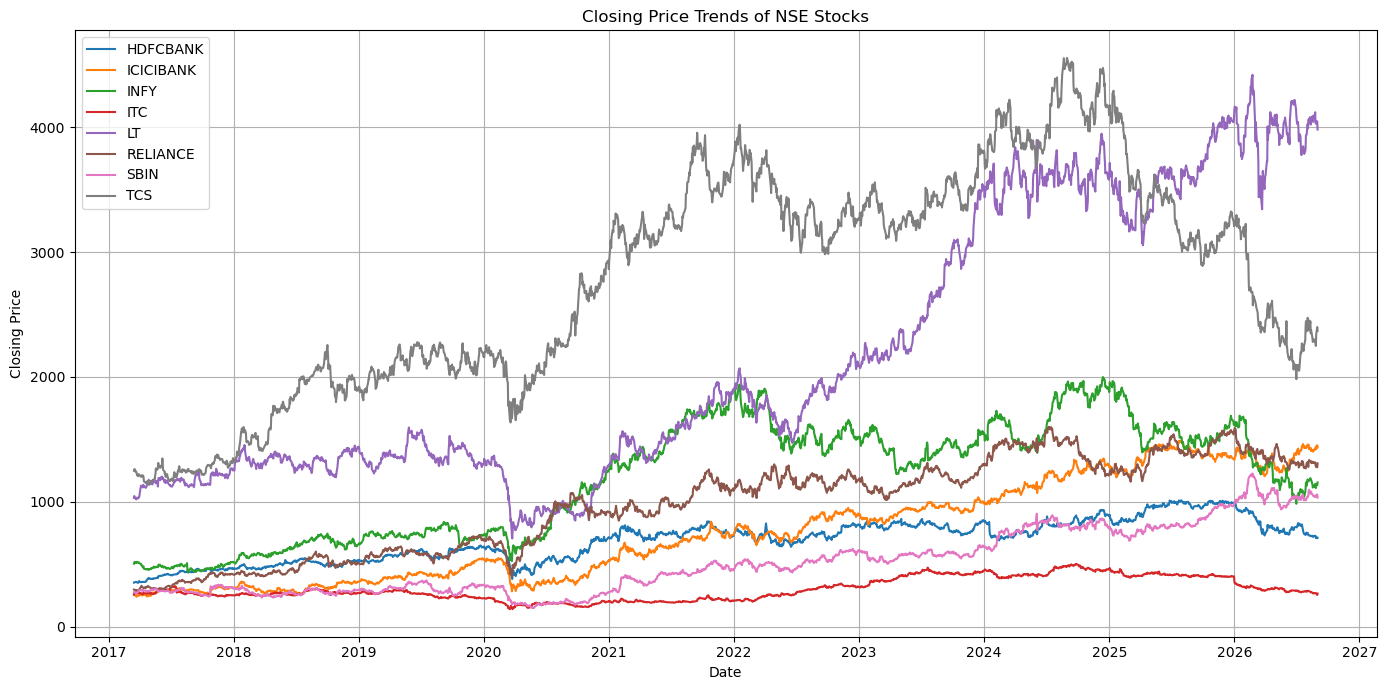

In [20]:
plt.figure(figsize=(14, 7))

for stock in stocks:
    stock_data = df[df["symbol"] == stock]
    plt.plot(
        stock_data["date"],
        stock_data["close"],
        label=stock
    )

plt.title("Closing Price Trends of NSE Stocks")
plt.xlabel("Date")
plt.ylabel("Closing Price")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

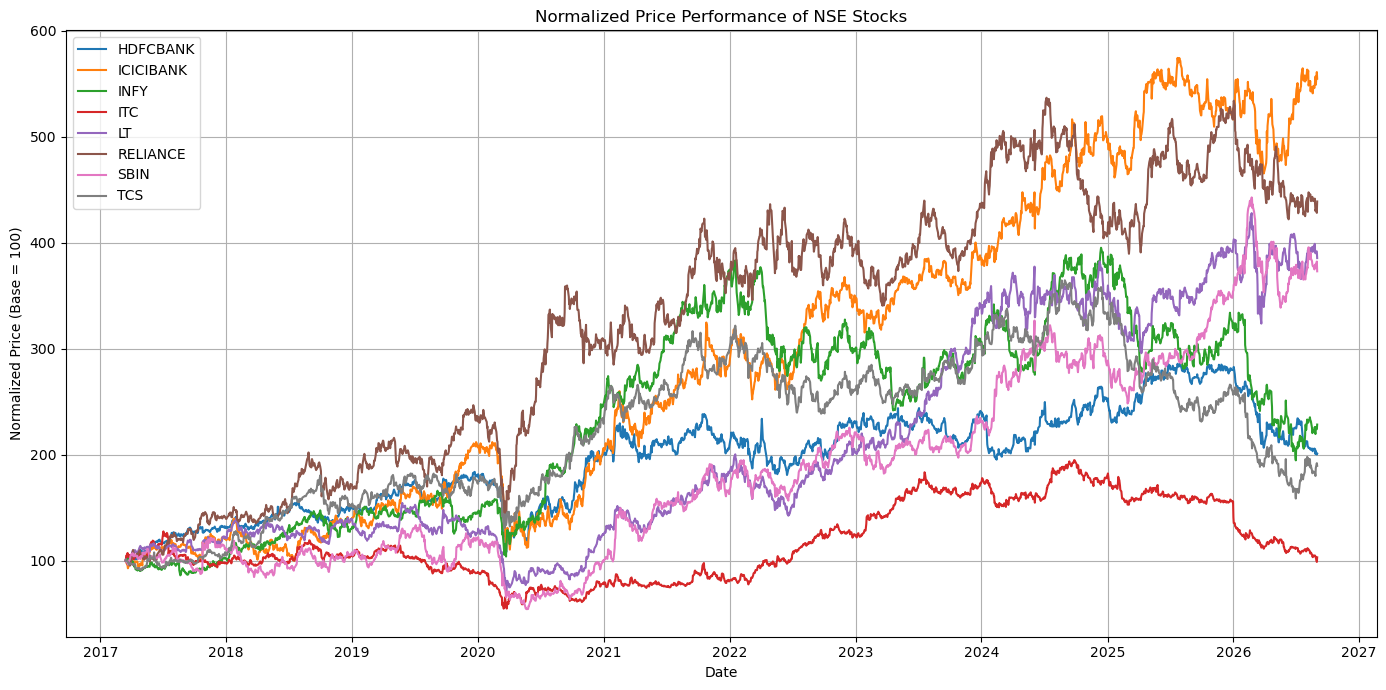

In [21]:
normalized_df = df.copy()

normalized_df["normalized_price"] = (
    normalized_df.groupby("symbol")["close"]
    .transform(lambda x: (x / x.iloc[0]) * 100)
)

plt.figure(figsize=(14, 7))

for stock in stocks:
    stock_data = normalized_df[
        normalized_df["symbol"] == stock
    ]

    plt.plot(
        stock_data["date"],
        stock_data["normalized_price"],
        label=stock
    )

plt.title("Normalized Price Performance of NSE Stocks")
plt.xlabel("Date")
plt.ylabel("Normalized Price (Base = 100)")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

In [22]:
return_stats = (
    df.groupby("symbol")["daily_return"]
    .agg(["mean", "std", "min", "max"])
    .round(6)
)

return_stats

,mean,std,min,max
symbol,,,,
HDFCBANK,0.000408,0.014715,-0.126069,0.115996
ICICIBANK,0.000896,0.018343,-0.178478,0.146877
INFY,0.000492,0.017193,-0.161881,0.120334
ITC,0.000131,0.015133,-0.124865,0.084337
LT,0.000712,0.016646,-0.162658,0.094352
RELIANCE,0.000782,0.017103,-0.131539,0.147180
SBIN,0.000768,0.020186,-0.144040,0.276872
TCS,0.000378,0.015262,-0.094103,0.098451


In [23]:
average_returns = (
    df.groupby("symbol")["daily_return"]
    .mean()
    .sort_values(ascending=False)
)

average_returns

symbol
ICICIBANK    0.000896
RELIANCE     0.000782
SBIN         0.000768
LT           0.000712
INFY         0.000492
HDFCBANK     0.000408
TCS          0.000378
ITC          0.000131
Name: daily_return, dtype: float64

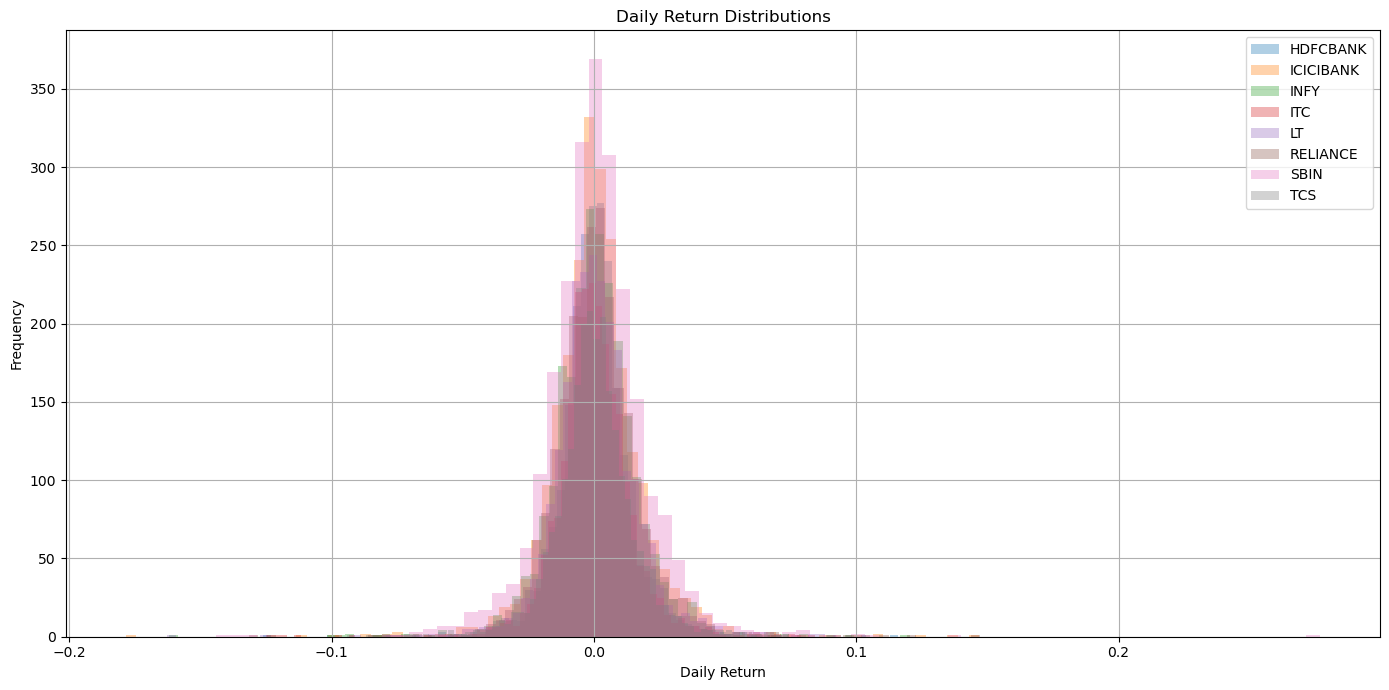

In [24]:
plt.figure(figsize=(14, 7))

for stock in stocks:
    stock_data = df[df["symbol"] == stock]

    plt.hist(
        stock_data["daily_return"].dropna(),
        bins=80,
        alpha=0.35,
        label=stock
    )

plt.title("Daily Return Distributions")
plt.xlabel("Daily Return")
plt.ylabel("Frequency")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

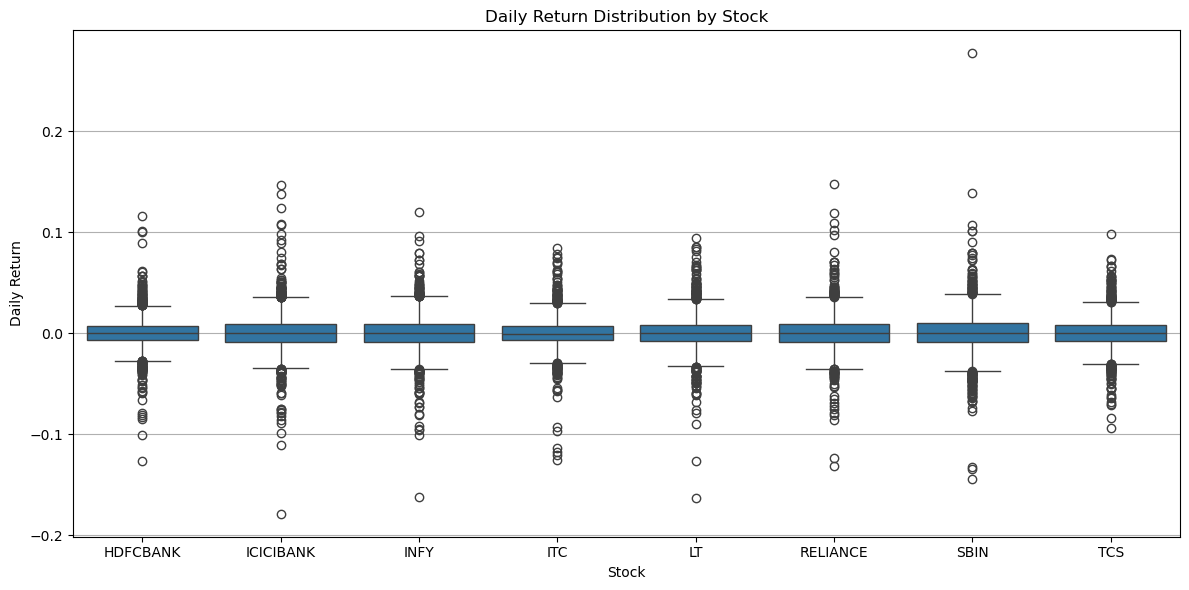

In [25]:
plt.figure(figsize=(12, 6))

sns.boxplot(
    data=df,
    x="symbol",
    y="daily_return"
)

plt.title("Daily Return Distribution by Stock")
plt.xlabel("Stock")
plt.ylabel("Daily Return")
plt.grid(True, axis="y")
plt.tight_layout()
plt.show()

In [26]:
return_volatility = (
    df.groupby("symbol")["daily_return"]
    .std()
    .sort_values(ascending=False)
)

print("Daily return standard deviation:")
print(return_volatility)

Daily return standard deviation:
symbol
SBIN         0.020186
ICICIBANK    0.018343
INFY         0.017193
RELIANCE     0.017103
LT           0.016646
TCS          0.015262
ITC          0.015133
HDFCBANK     0.014715
Name: daily_return, dtype: float64


In [27]:
volatility_columns = [
    col for col in df.columns
    if "volatility" in col.lower()
]

print("Volatility columns:")
print(volatility_columns)

Volatility columns:
['volatility_5d', 'volatility_10d', 'volatility_20d', 'target_5d_volatility']


In [28]:
if "volatility_20d" in df.columns:
    volatility_col = "volatility_20d"
elif "volatility_20" in df.columns:
    volatility_col = "volatility_20"
else:
    volatility_col = volatility_columns[-1]

print("Selected volatility column:", volatility_col)

Selected volatility column: volatility_20d


In [29]:
volatility_stats = (
    df.groupby("symbol")[volatility_col]
    .agg(["mean", "min", "max", "std"])
    .round(4)
)

volatility_stats

,mean,min,max,std
symbol,,,,
HDFCBANK,0.2064,0.0712,1.0259,0.1109
ICICIBANK,0.2544,0.0757,1.2381,0.1438
INFY,0.2525,0.1046,0.9699,0.1066
ITC,0.2173,0.0748,0.9945,0.1043
LT,0.2427,0.0969,1.0179,0.1062
RELIANCE,0.2464,0.0884,1.2288,0.1150
SBIN,0.2846,0.0914,1.0723,0.1389
TCS,0.2267,0.0924,0.7910,0.0852


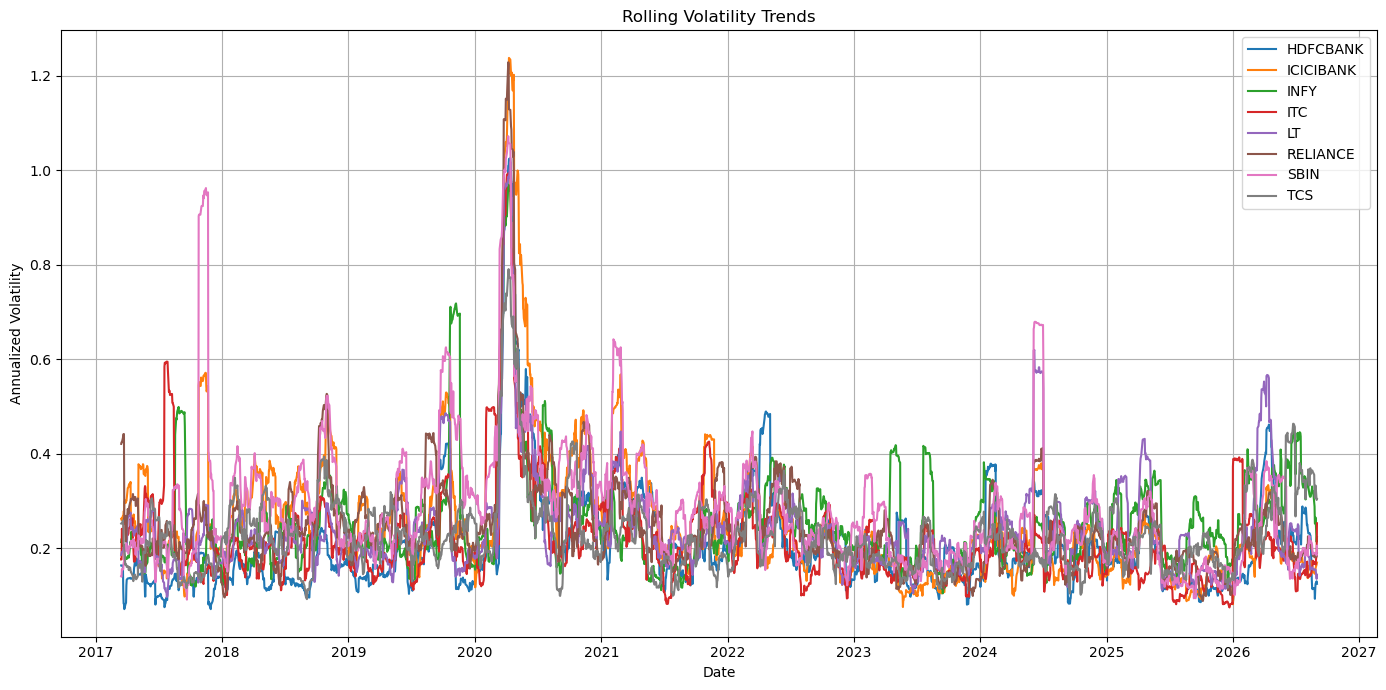

In [30]:
plt.figure(figsize=(14, 7))

for stock in stocks:
    stock_data = df[df["symbol"] == stock]

    plt.plot(
        stock_data["date"],
        stock_data[volatility_col],
        label=stock
    )

plt.title("Rolling Volatility Trends")
plt.xlabel("Date")
plt.ylabel("Annualized Volatility")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

In [31]:
highest_volatility = (
    df[["date", "symbol", volatility_col]]
    .dropna()
    .sort_values(volatility_col, ascending=False)
    .head(15)
)

highest_volatility

,date,symbol,volatility_20d
3098,2020-04-09,ICICIBANK,1.238088
3099,2020-04-13,ICICIBANK,1.234424
12468,2020-04-07,RELIANCE,1.228787
12469,2020-04-08,RELIANCE,1.225067
3102,2020-04-17,ICICIBANK,1.207266
3096,2020-04-07,ICICIBANK,1.205712
3097,2020-04-08,ICICIBANK,1.204446
3100,2020-04-15,ICICIBANK,1.204223
3106,2020-04-23,ICICIBANK,1.202383
3104,2020-04-21,ICICIBANK,1.201870


In [32]:
ma_columns = [
    col for col in df.columns
    if col.lower().startswith("ma_")
]

print("Moving average columns:")
print(ma_columns)

Moving average columns:
['ma_5', 'ma_10', 'ma_20', 'ma_50']


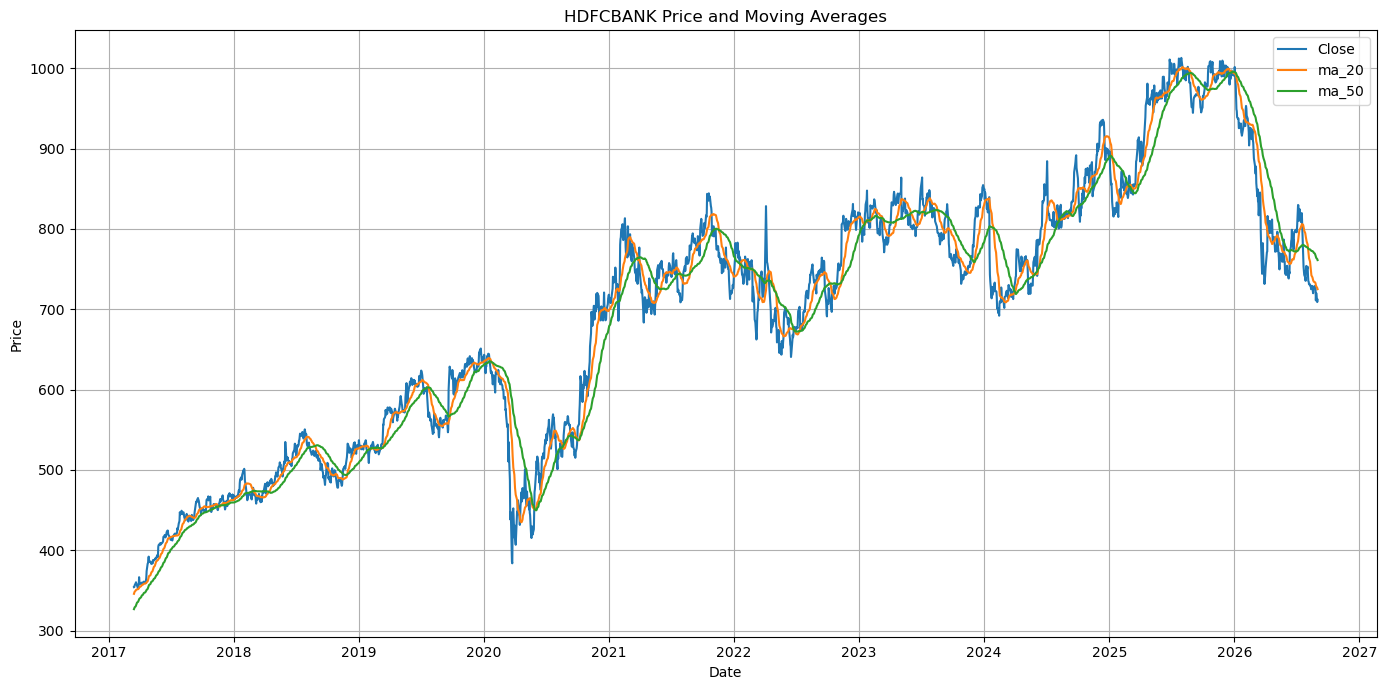

In [33]:
selected_stock = stocks[0]

stock_data = df[
    df["symbol"] == selected_stock
].copy()

plt.figure(figsize=(14, 7))

plt.plot(
    stock_data["date"],
    stock_data["close"],
    label="Close"
)

for ma in ["ma_20", "ma_50"]:
    if ma in stock_data.columns:
        plt.plot(
            stock_data["date"],
            stock_data[ma],
            label=ma
        )

plt.title(f"{selected_stock} Price and Moving Averages")
plt.xlabel("Date")
plt.ylabel("Price")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

In [34]:
momentum_columns = [
    col for col in df.columns
    if "momentum" in col.lower()
]

print("Momentum columns:")
print(momentum_columns)

Momentum columns:
['momentum_5d', 'momentum_20d']


In [35]:
momentum_stats = (
    df.groupby("symbol")[momentum_columns]
    .mean()
    .round(4)
)

momentum_stats

,momentum_5d,momentum_20d
symbol,,
HDFCBANK,0.0021,0.0083
ICICIBANK,0.0045,0.0178
INFY,0.0024,0.0098
ITC,0.0006,0.0028
LT,0.0037,0.0149
RELIANCE,0.0039,0.0165
SBIN,0.0039,0.0164
TCS,0.0018,0.0077


In [37]:
if "momentum_20" in df.columns:

    plt.figure(figsize=(14, 7))

    for stock in stocks:
        stock_data = df[df["symbol"] == stock]

        plt.plot(
            stock_data["date"],
            stock_data["momentum_20"],
            label=stock
        )

    plt.title("20-Day Momentum of NSE Stocks")
    plt.xlabel("Date")
    plt.ylabel("Momentum")
    plt.legend()
    plt.grid(True)
    plt.tight_layout()
    plt.show()

In [38]:
drawdown_stats = (
    df.groupby("symbol")["drawdown"]
    .agg(["min", "mean", "max"])
    .round(4)
)

drawdown_stats

,min,mean,max
symbol,,,
HDFCBANK,-0.4105,-0.0812,0.0
ICICIBANK,-0.4831,-0.0820,0.0
INFY,-0.5073,-0.1388,0.0
ITC,-0.5701,-0.2191,0.0
LT,-0.5565,-0.1046,0.0
RELIANCE,-0.4509,-0.0919,0.0
SBIN,-0.5949,-0.1314,0.0
TCS,-0.5646,-0.1303,0.0


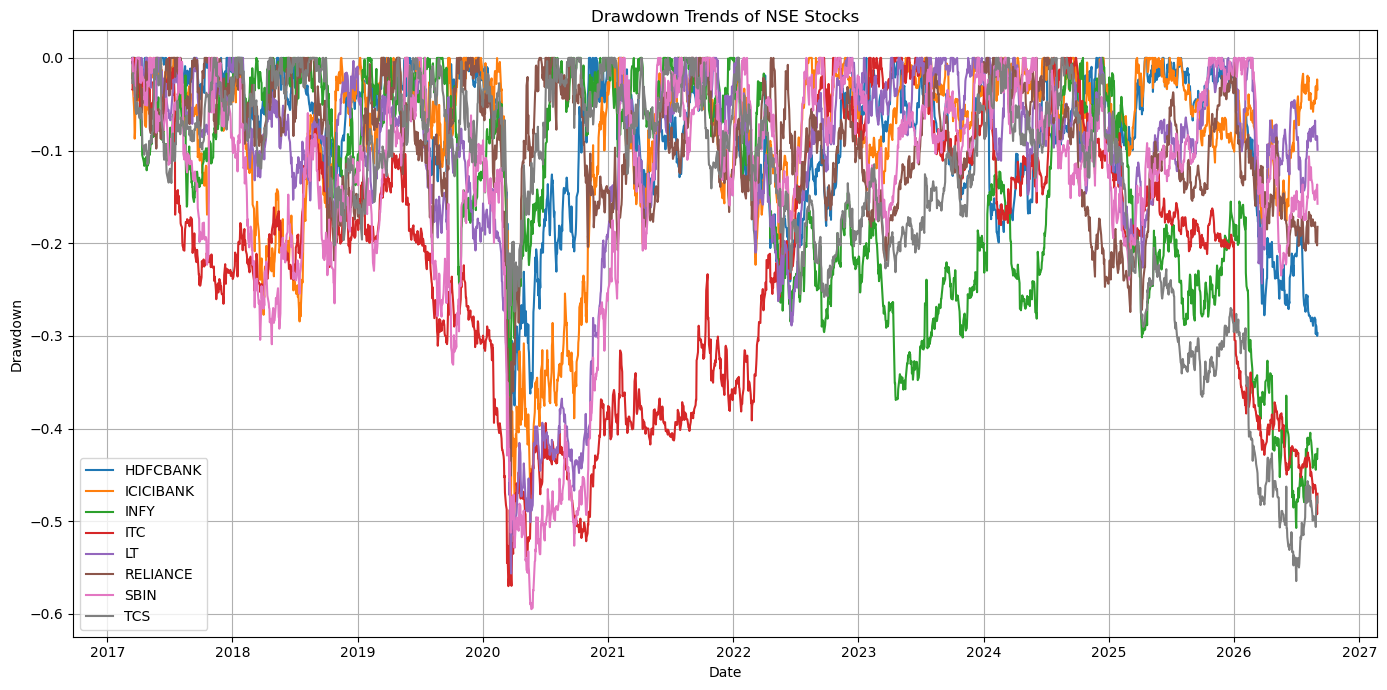

In [39]:
plt.figure(figsize=(14, 7))

for stock in stocks:
    stock_data = df[df["symbol"] == stock]

    plt.plot(
        stock_data["date"],
        stock_data["drawdown"],
        label=stock
    )

plt.title("Drawdown Trends of NSE Stocks")
plt.xlabel("Date")
plt.ylabel("Drawdown")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

In [40]:
max_drawdown = (
    df.groupby("symbol")["drawdown"]
    .min()
    .sort_values()
)

print("Maximum drawdown by stock:")
print(max_drawdown)

Maximum drawdown by stock:
symbol
SBIN        -0.594925
ITC         -0.570073
TCS         -0.564623
LT          -0.556454
INFY        -0.507276
ICICIBANK   -0.483072
RELIANCE    -0.450884
HDFCBANK    -0.410550
Name: drawdown, dtype: float64


In [41]:
volume_stats = (
    df.groupby("symbol")["volume"]
    .agg(["mean", "median", "min", "max", "std"])
)

volume_stats

,mean,median,min,max,std
symbol,,,,,
HDFCBANK,2.172493e+07,16712264.0,0,445342100,2.117974e+07
ICICIBANK,1.823414e+07,14617079.0,0,286857658,1.387207e+07
INFY,8.426580e+06,6892490.0,0,164404960,7.055272e+06
ITC,1.786393e+07,13371177.0,0,431851622,1.743636e+07
LT,2.694190e+06,2113862.0,0,21153346,1.900511e+06
RELIANCE,1.792075e+07,14165188.0,0,142683366,1.335805e+07
SBIN,2.428383e+07,16725013.0,0,262677081,2.197060e+07
TCS,2.855293e+06,2405370.0,0,88067154,2.529168e+06


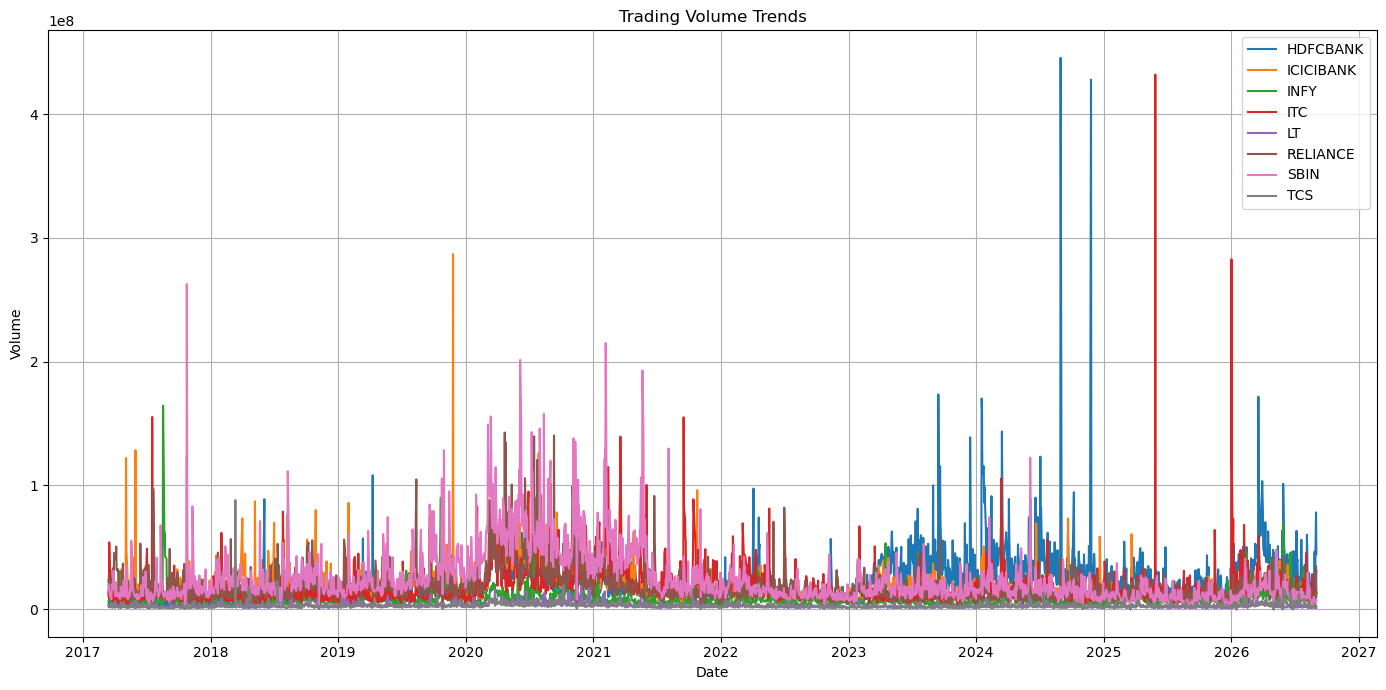

In [42]:
plt.figure(figsize=(14, 7))

for stock in stocks:
    stock_data = df[df["symbol"] == stock]

    plt.plot(
        stock_data["date"],
        stock_data["volume"],
        label=stock
    )

plt.title("Trading Volume Trends")
plt.xlabel("Date")
plt.ylabel("Volume")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

In [43]:
returns_pivot = df.pivot(
    index="date",
    columns="symbol",
    values="daily_return"
)

returns_pivot.head()

symbol,HDFCBANK,ICICIBANK,INFY,ITC,LT,RELIANCE,SBIN,TCS
date,,,,,,,,
2017-03-15,0.004182,-0.007311,-0.022082,0.004118,-0.005905,0.011981,0.009831,-0.026952
2017-03-16,0.000529,-0.002280,0.016700,0.000932,0.014301,-0.005594,0.007031,0.009046
2017-03-17,0.005997,-0.013708,0.011129,0.047681,-0.011776,0.002350,-0.018439,0.001924
2017-03-20,0.007189,-0.019779,-0.018072,0.002311,-0.009597,-0.015299,-0.000912,-0.018113
2017-03-21,0.003377,-0.010907,0.011111,0.021284,0.007414,-0.013273,-0.005659,0.002702


In [44]:
return_correlation = returns_pivot.corr()

return_correlation.round(3)

symbol,HDFCBANK,ICICIBANK,INFY,ITC,LT,RELIANCE,SBIN,TCS
symbol,,,,,,,,
HDFCBANK,1.000,0.527,0.262,0.278,0.475,0.393,0.423,0.235
ICICIBANK,0.527,1.000,0.236,0.287,0.492,0.361,0.637,0.204
INFY,0.262,0.236,1.000,0.170,0.253,0.258,0.191,0.634
ITC,0.278,0.287,0.170,1.000,0.315,0.263,0.324,0.177
LT,0.475,0.492,0.253,0.315,1.000,0.377,0.503,0.241
RELIANCE,0.393,0.361,0.258,0.263,0.377,1.000,0.364,0.274
SBIN,0.423,0.637,0.191,0.324,0.503,0.364,1.000,0.172
TCS,0.235,0.204,0.634,0.177,0.241,0.274,0.172,1.000


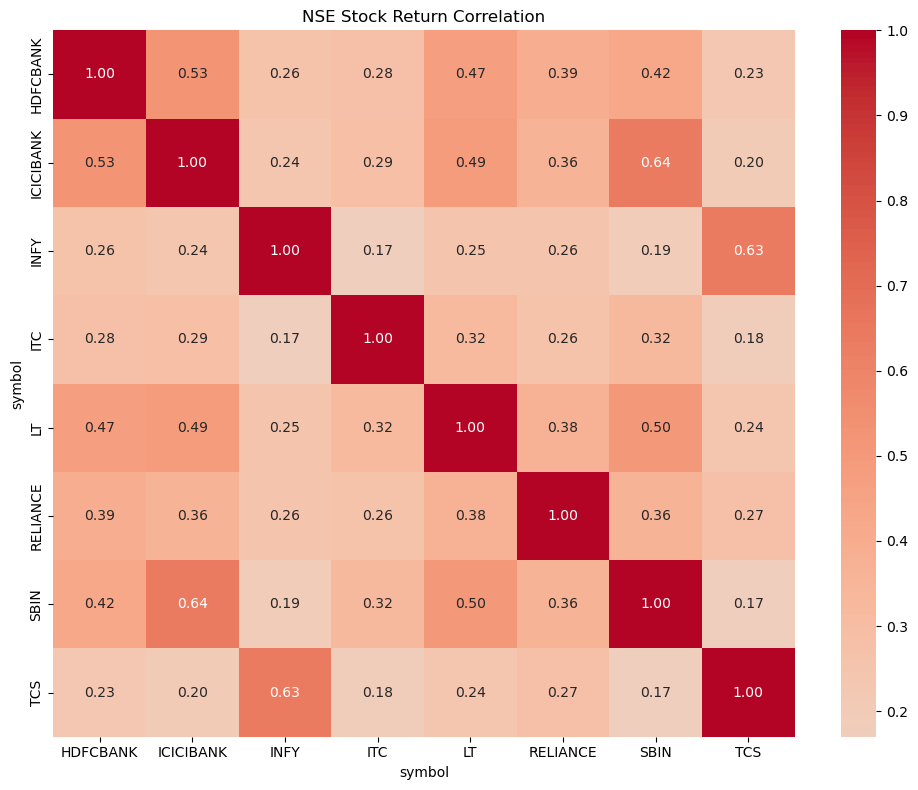

In [45]:
plt.figure(figsize=(10, 8))

sns.heatmap(
    return_correlation,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    center=0
)

plt.title("NSE Stock Return Correlation")
plt.tight_layout()
plt.show()

In [46]:
target_column = "target_5d_volatility"

print("Target column:", target_column)

print("\nTarget statistics:")
print(df[target_column].describe())

Target column: target_5d_volatility

Target statistics:
count    18744.000000
mean         0.223860
std          0.149638
min          0.016310
25%          0.132857
50%          0.189265
75%          0.269226
max          1.852513
Name: target_5d_volatility, dtype: float64


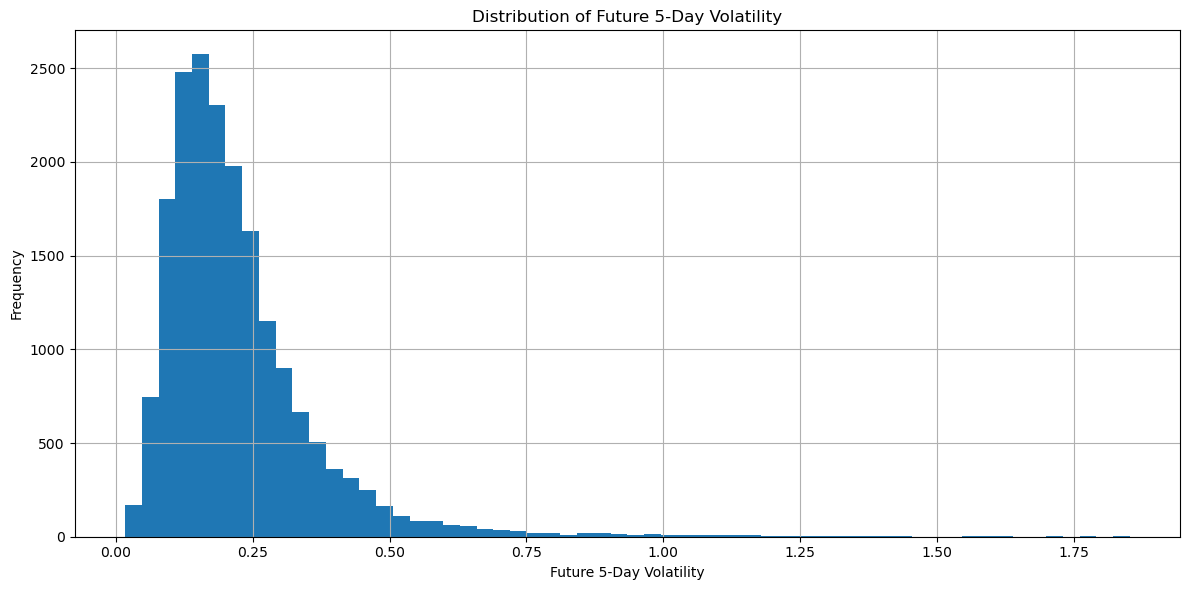

In [47]:
plt.figure(figsize=(12, 6))

plt.hist(
    df[target_column].dropna(),
    bins=60
)

plt.title("Distribution of Future 5-Day Volatility")
plt.xlabel("Future 5-Day Volatility")
plt.ylabel("Frequency")
plt.grid(True)
plt.tight_layout()
plt.show()

In [48]:
target_stats = (
    df.groupby("symbol")[target_column]
    .agg(["mean", "median", "std", "min", "max"])
    .round(4)
)

target_stats

,mean,median,std,min,max
symbol,,,,,
HDFCBANK,0.1907,0.1559,0.1365,0.0163,1.4413
ICICIBANK,0.2385,0.1952,0.1737,0.0184,1.7280
INFY,0.2345,0.2001,0.1432,0.0267,1.3784
ITC,0.2005,0.1718,0.1356,0.0228,1.3584
LT,0.2233,0.1923,0.1416,0.0180,1.7199
RELIANCE,0.2283,0.2013,0.1453,0.0293,1.8470
SBIN,0.2632,0.2230,0.1791,0.0196,1.8525
TCS,0.2119,0.1840,0.1208,0.0266,0.9681


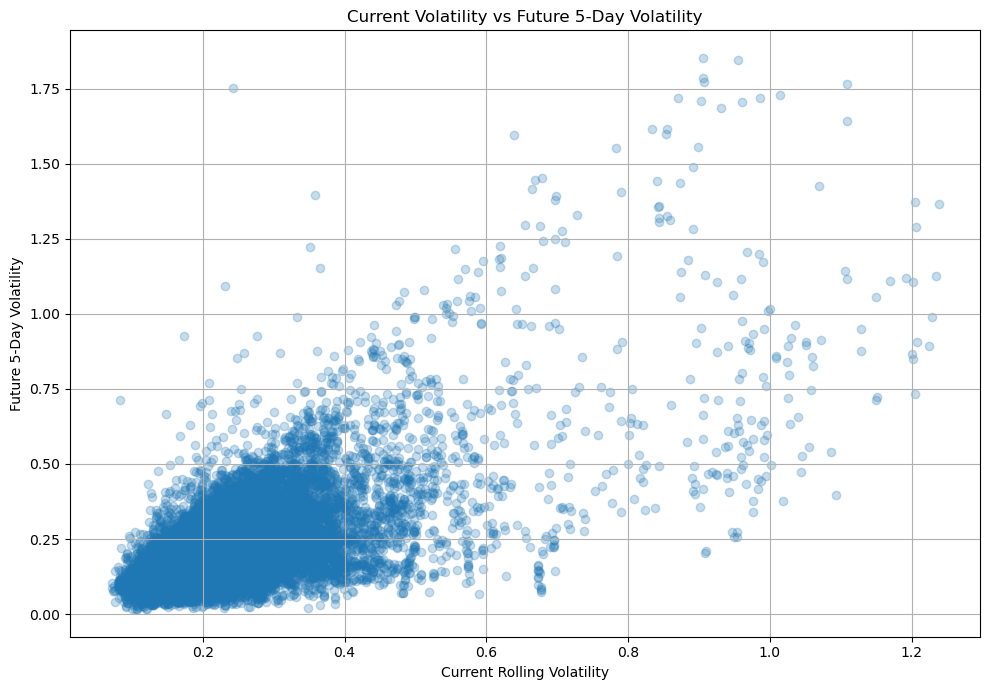

In [49]:
plt.figure(figsize=(10, 7))

plt.scatter(
    df[volatility_col],
    df[target_column],
    alpha=0.25
)

plt.title("Current Volatility vs Future 5-Day Volatility")
plt.xlabel("Current Rolling Volatility")
plt.ylabel("Future 5-Day Volatility")
plt.grid(True)
plt.tight_layout()
plt.show()

In [50]:
numeric_df = df.select_dtypes(include=np.number)

correlation_matrix = numeric_df.corr()

print("Correlation matrix created.")
print(correlation_matrix.shape)

Correlation matrix created.
(23, 23)


In [51]:
target_correlations = (
    correlation_matrix[target_column]
    .sort_values(ascending=False)
)

target_correlations

target_5d_volatility    1.000000
volatility_5d           0.875275
volatility_10d          0.750403
volatility_20d          0.644148
price_range             0.638124
volume                  0.365815
volume_ma_20            0.276377
volume_ratio            0.267942
daily_return            0.019104
intraday_return         0.018120
log_return              0.003762
momentum_5d            -0.028415
ma_50                  -0.080677
ma_20                  -0.087858
high                   -0.089893
ma_10                  -0.090910
ma_5                   -0.092534
close                  -0.092875
open                   -0.092962
adj_close              -0.094052
low                    -0.096192
momentum_20d           -0.141781
drawdown               -0.255594
Name: target_5d_volatility, dtype: float64

In [52]:
strongest_features = (
    target_correlations
    .drop(target_column)
    .sort_values(key=abs, ascending=False)
)

strongest_features.head(15)

volatility_5d     0.875275
volatility_10d    0.750403
volatility_20d    0.644148
price_range       0.638124
volume            0.365815
volume_ma_20      0.276377
volume_ratio      0.267942
drawdown         -0.255594
momentum_20d     -0.141781
low              -0.096192
adj_close        -0.094052
open             -0.092962
close            -0.092875
ma_5             -0.092534
ma_10            -0.090910
Name: target_5d_volatility, dtype: float64

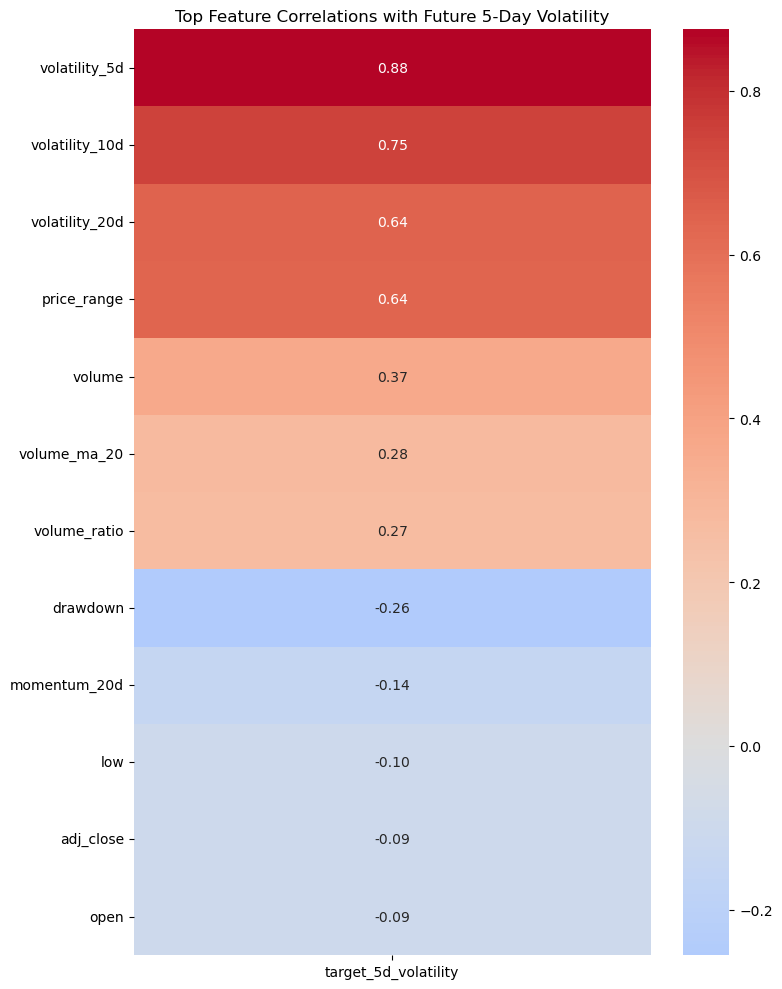

In [53]:
top_features = (
    strongest_features
    .head(12)
    .index
)

plt.figure(figsize=(8, 10))

sns.heatmap(
    correlation_matrix.loc[
        top_features,
        [target_column]
    ],
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    center=0
)

plt.title("Top Feature Correlations with Future 5-Day Volatility")
plt.tight_layout()
plt.show()

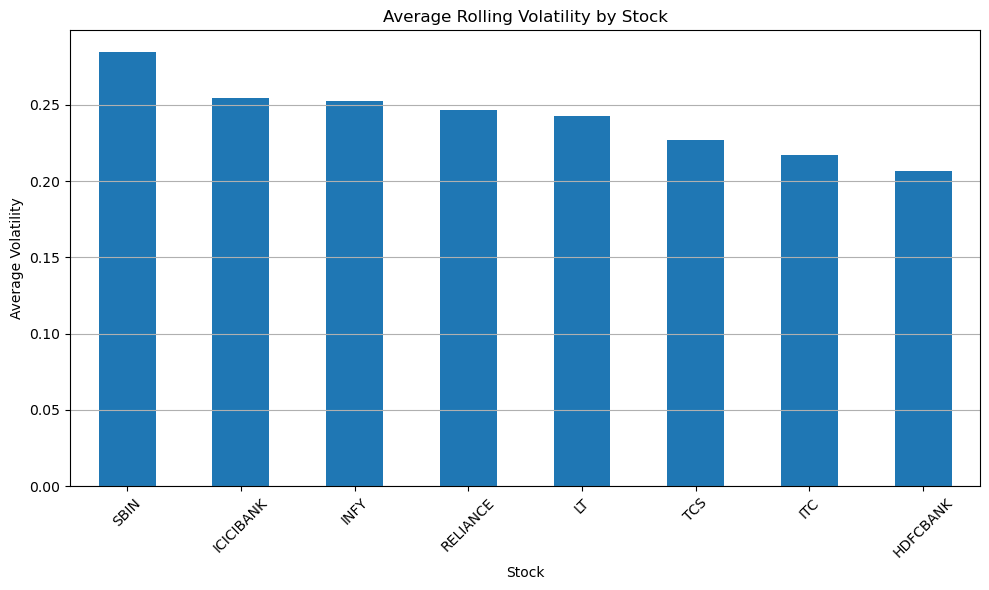

In [54]:
mean_volatility = (
    df.groupby("symbol")[volatility_col]
    .mean()
    .sort_values(ascending=False)
)

plt.figure(figsize=(10, 6))

mean_volatility.plot(kind="bar")

plt.title("Average Rolling Volatility by Stock")
plt.xlabel("Stock")
plt.ylabel("Average Volatility")
plt.xticks(rotation=45)
plt.grid(True, axis="y")
plt.tight_layout()
plt.show()

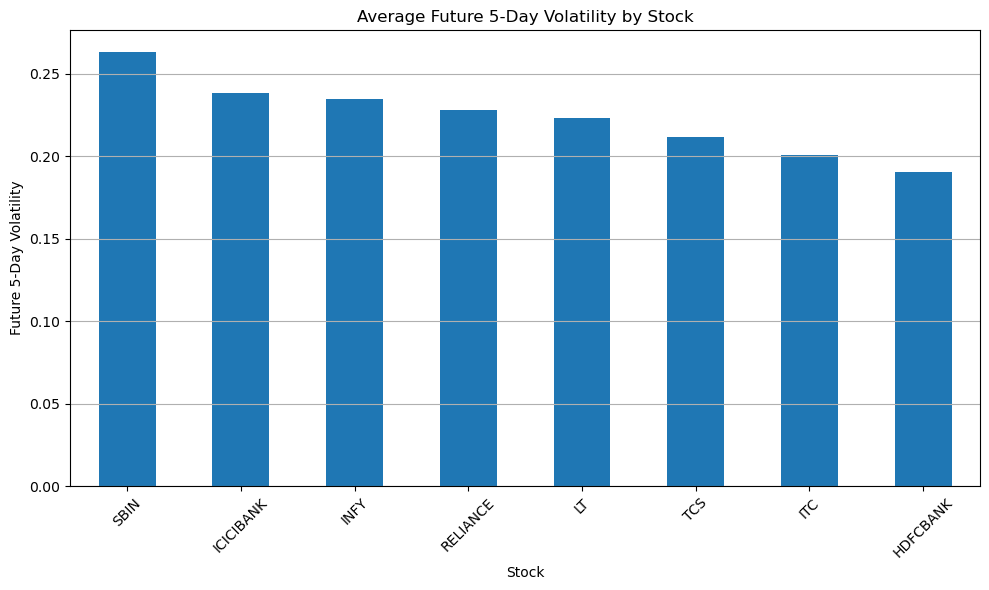

In [55]:
mean_future_volatility = (
    df.groupby("symbol")[target_column]
    .mean()
    .sort_values(ascending=False)
)

plt.figure(figsize=(10, 6))

mean_future_volatility.plot(kind="bar")

plt.title("Average Future 5-Day Volatility by Stock")
plt.xlabel("Stock")
plt.ylabel("Future 5-Day Volatility")
plt.xticks(rotation=45)
plt.grid(True, axis="y")
plt.tight_layout()
plt.show()

In [56]:
largest_positive_returns = (
    df[["date", "symbol", "daily_return"]]
    .dropna()
    .sort_values("daily_return", ascending=False)
    .head(15)
)

largest_positive_returns

,date,symbol,daily_return
14210,2017-10-25,SBIN,0.276872
12461,2020-03-25,RELIANCE,0.147180
2495,2017-10-25,ICICIBANK,0.146877
14796,2020-03-13,SBIN,0.138288
3096,2020-04-07,ICICIBANK,0.137624
3302,2021-02-01,ICICIBANK,0.124395
5431,2020-03-24,INFY,0.120334
12468,2020-04-07,RELIANCE,0.119402
746,2020-03-25,HDFCBANK,0.115996
12458,2020-03-20,RELIANCE,0.109241


In [57]:
largest_negative_returns = (
    df[["date", "symbol", "daily_return"]]
    .dropna()
    .sort_values("daily_return")
    .head(15)
)

largest_negative_returns

,date,symbol,daily_return
3087,2020-03-23,ICICIBANK,-0.178478
10116,2020-03-23,LT,-0.162658
5325,2019-10-22,INFY,-0.161881
15840,2024-06-04,SBIN,-0.144040
14802,2020-03-23,SBIN,-0.134620
14795,2020-03-12,SBIN,-0.132599
12459,2020-03-23,RELIANCE,-0.131539
11154,2024-06-04,LT,-0.126746
744,2020-03-23,HDFCBANK,-0.126069
7114,2017-07-18,ITC,-0.124865


In [58]:
print("Missing values:")
print(df.isnull().sum().sum())

Missing values:
0


In [59]:
print("Duplicate rows:", df.duplicated().sum())

Duplicate rows: 0


In [60]:
symbol_date_duplicates = (
    df.duplicated(
        subset=["symbol", "date"]
    ).sum()
)

print("Duplicate symbol-date records:", symbol_date_duplicates)

Duplicate symbol-date records: 0


In [61]:
print("=" * 60)
print("NSE STOCKS EDA SUMMARY")
print("=" * 60)

print("\nDataset:")
print("Rows:", len(df))
print("Columns:", len(df.columns))
print("Stocks:", df["symbol"].nunique())
print("Start date:", df["date"].min())
print("End date:", df["date"].max())

print("\nData Quality:")
print("Missing values:", df.isnull().sum().sum())
print("Duplicate rows:", df.duplicated().sum())

print("\nAverage Daily Return:")
print(df.groupby("symbol")["daily_return"].mean().round(6))

print("\nAverage Rolling Volatility:")
print(df.groupby("symbol")[volatility_col].mean().round(4))

print("\nAverage Future 5-Day Volatility:")
print(df.groupby("symbol")[target_column].mean().round(4))

print("\nMaximum Drawdown:")
print(df.groupby("symbol")["drawdown"].min().round(4))

print("\nEDA completed successfully.")

NSE STOCKS EDA SUMMARY

Dataset:
Rows: 18744
Columns: 25
Stocks: 8
Start date: 2017-03-15 00:00:00
End date: 2026-09-01 00:00:00

Data Quality:
Missing values: 0
Duplicate rows: 0

Average Daily Return:
symbol
HDFCBANK     0.000408
ICICIBANK    0.000896
INFY         0.000492
ITC          0.000131
LT           0.000712
RELIANCE     0.000782
SBIN         0.000768
TCS          0.000378
Name: daily_return, dtype: float64

Average Rolling Volatility:
symbol
HDFCBANK     0.2064
ICICIBANK    0.2544
INFY         0.2525
ITC          0.2173
LT           0.2427
RELIANCE     0.2464
SBIN         0.2846
TCS          0.2267
Name: volatility_20d, dtype: float64

Average Future 5-Day Volatility:
symbol
HDFCBANK     0.1907
ICICIBANK    0.2385
INFY         0.2345
ITC          0.2005
LT           0.2233
RELIANCE     0.2283
SBIN         0.2632
TCS          0.2119
Name: target_5d_volatility, dtype: float64

Maximum Drawdown:
symbol
HDFCBANK    -0.4105
ICICIBANK   -0.4831
INFY        -0.5073
ITC         -0.5

In [62]:
eda_summary = pd.DataFrame({
    "average_daily_return": df.groupby("symbol")["daily_return"].mean(),
    "average_volatility": df.groupby("symbol")[volatility_col].mean(),
    "average_future_5d_volatility": df.groupby("symbol")[target_column].mean(),
    "maximum_drawdown": df.groupby("symbol")["drawdown"].min(),
    "average_volume": df.groupby("symbol")["volume"].mean()
}).reset_index()

eda_summary

,symbol,average_daily_return,average_volatility,average_future_5d_volatility,maximum_drawdown,average_volume
0,HDFCBANK,0.000408,0.206437,0.190710,-0.410550,2.172493e+07
1,ICICIBANK,0.000896,0.254448,0.238527,-0.483072,1.823414e+07
2,INFY,0.000492,0.252549,0.234457,-0.507276,8.426580e+06
3,ITC,0.000131,0.217271,0.200483,-0.570073,1.786393e+07
4,LT,0.000712,0.242748,0.223289,-0.556454,2.694190e+06
5,RELIANCE,0.000782,0.246396,0.228315,-0.450884,1.792075e+07
6,SBIN,0.000768,0.284619,0.263172,-0.594925,2.428383e+07
7,TCS,0.000378,0.226689,0.211922,-0.564623,2.855293e+06


In [63]:
summary_path = Path("../data/processed/nse_stocks_eda_summary.csv")

eda_summary.to_csv(
    summary_path,
    index=False
)

print("EDA summary saved to:")
print(summary_path)

EDA summary saved to:
..\data\processed\nse_stocks_eda_summary.csv
